## Ejercicio 5

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [2]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [3]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [4]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

### Inciso a)

In [ ]:
# Agrupamos las matrices de proyección según cantidad de direcciones
matrices = {2: A2, 4: A4, 7: A7}
mediciones = {}
reconstrucciones = {}

# Por cada tupla (k, matriz de proyeccion) de 'matrices'
for k, A in matrices.items():
    # Generamos las mediciones del fantoma a partir del producto matricial A x_fantoma
    b = A @ x_fantoma

    # Resolvemos por mínimos cuadrados usando np.linalg.lstq()
    x_rec = np.linalg.lstsq(A, b, rcond=None)[0]    # [0] selecciona el vector solución

     # Guardamos los resultados de cada caso para cada k, A (2,4,7 direcciones)
    mediciones[k] = b
    reconstrucciones[k] = x_rec

### Inciso b)

In [ ]:
# Recuperamos la matriz, las mediciones y la reconstrucción del inciso a)
for k in [2, 4, 7]:

    A = matrices[k]
    b = mediciones[k]
    x_rec = reconstrucciones[k]

    rango = np.linalg.matrix_rank(A)

    # El residuo es la diferencia entre las mediciones originales y las reconstruidas
    residuo = b - A @ x_rec
    norma_residuo = np.linalg.norm(residuo)

    # Dividimos la distancia al fantoma por su norma para obtener el error relativo
    error_relativo = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)

    print("Matriz: A" + str(k))
    print("Rango:", rango)
    print("Norma del residuo:", norma_residuo)
    print("Error relativo:", error_relativo, "\n")

Matriz: A2
Rango: 15
Norma del residuo: 4.047273077394497e-15
Error relativo: 0.46892654788302063

Matriz: A4
Rango: 39
Norma del residuo: 9.742073111787737e-15
Error relativo: 0.1364605407341871

Matriz: A7
Rango: 64
Norma del residuo: 1.673576926985556e-14
Error relativo: 2.5738652865518797e-15



| Matriz | Rango | Norma del residuo | Error relativo |
| --- | --- | --- | --- |
| A2 | 15 | 4.0345e-15 | 4.689265e-01 |
| A4 | 39 | 1.5080e-14 | 1.364605e-01 |
| A7 | 64 | 1.3111e-14 | 1.667070e-15 |

### Inciso c)

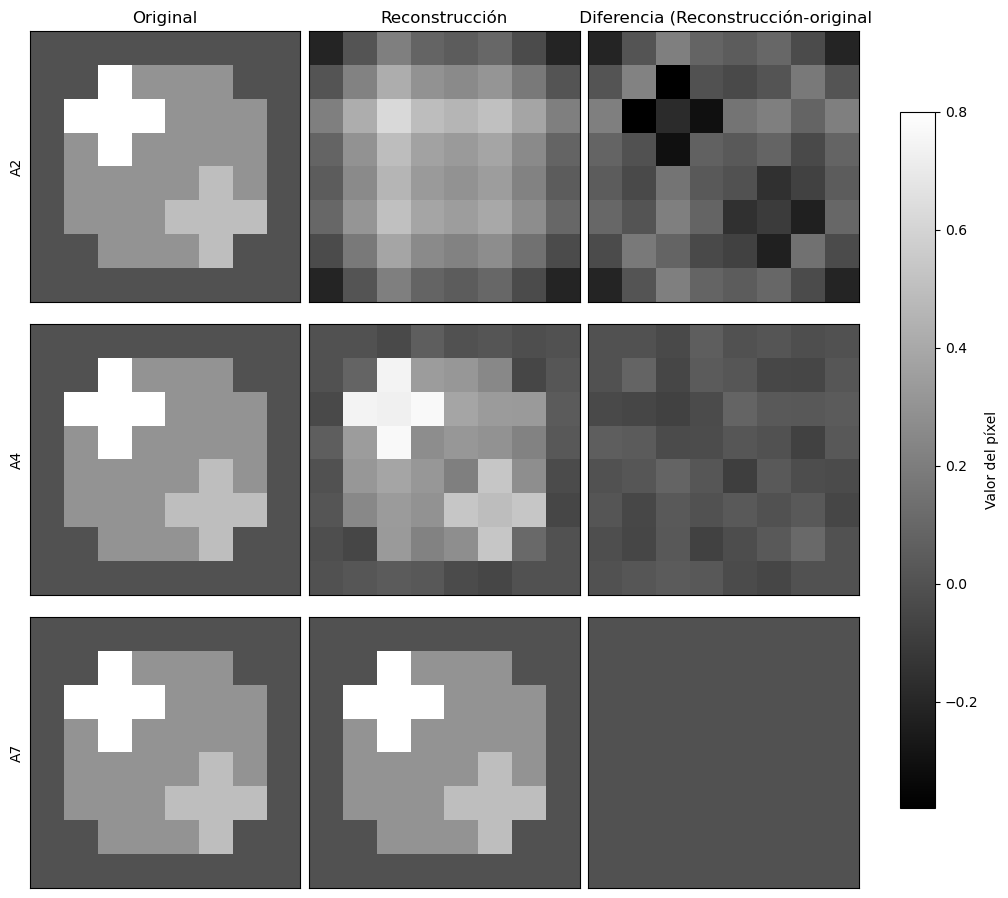

In [ ]:
# Reunimos las imágenes originales, las reconstrucciones y sus diferencias.
imagenes = []
for k in matrices:
    X_rec = reconstrucciones[k].reshape(n, n)
    imagenes.extend([X_fantoma, X_rec, X_rec - X_fantoma])

# Elegimos límites comunes para usar la misma escala de grises en todos los gráficos.
vmin = min(imagen.min() for imagen in imagenes)
vmax = max(imagen.max() for imagen in imagenes)

# Cada fila corresponde a una matriz: A2, A4 o A7.
fig, axs = plt.subplots(3, 3, figsize=(10, 9), layout="constrained")
for fila, k in enumerate(matrices):
    X_rec = reconstrucciones[k].reshape(n, n)
    # Las columnas muestran el original, la reconstrucción y la diferencia.
    for columna, imagen in enumerate([X_fantoma, X_rec, X_rec - X_fantoma]):
        im = axs[fila, columna].imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)
        axs[fila, columna].set_xticks([])
        axs[fila, columna].set_yticks([])
    axs[fila, 0].set_ylabel(f"A{k}")

# Agregamos los títulos de las columnas y una barra de colores compartida.
for ax, titulo in zip(axs[0], ["Original", "Reconstrucción", " Diferencia (Reconstrucción-original)"]):
    ax.set_title(titulo)
fig.colorbar(axs[0, 0].images[0], ax=axs, label="Valor del píxel", shrink=0.8)
plt.show()

Como vimos antes en la tabla, con **A2** el error relativo es aproximadamente 0,469 y con **A4** es 0,136. Con **A7** se recupera el fantoma con error $10^{-15}$, que es prácticamente nulo. Un residuo casi cero indica que la imagen reconstruida es capaz de reproducir las mediciones prácticamente igual que el fantoma original. <br><br>
Es decir, En **A2** y **A4**, la diferencia entre la reconstrucción y el fantoma puede ser un vector no nulo del espacio nulo. En cambio, en **A7** no hay esa ambigüedad porque tiene el rango columna completo.